In [1]:
# Configuration: edit this JSON file, then restart the kernel and Run All.
from pathlib import Path
import sys

REPO_ROOT = next((p for p in [Path.cwd(), *Path.cwd().parents]
                  if (p / "functions.py").is_file() and (p / "applications/configs").is_dir()), None)
if REPO_ROOT is None:
    raise RuntimeError("Open this notebook from the repository root or applications/ folder")
sys.path.insert(0, str(REPO_ROOT))
from reporting import (load_application_config, repo_path, utc_timestamp,
                       select_analysis_window, select_snapshot_time,
                       capture_summary, export_application_results)
CONFIG_PATH = repo_path(REPO_ROOT, globals().get("CONFIG_PATH", REPO_ROOT / "applications/configs/latte_adcp_satellite.json"))
config = load_application_config(CONFIG_PATH, "latte_adcp_satellite", REPO_ROOT)
analysis, plot_config = config["analysis"], config["plot"]
outer_fit_kwargs = {"maxfev": config["outer_fit"]["maxfev"], "Rc_max": config["outer_fit"]["Rc_max_m"]}

import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
import netCDF4 as nc
import xarray as xr
import scipy.io as sio
from datetime import datetime, timedelta

from functions import plot_outer_core_fit, decode_ce23_mat_time, interpolate_satellite_at_time, latte, latte_source_selector, axis_ratio_from_Q, tangential_velocity, out_core_param_fit, model_uv_at_xy, vector_R2

from manuscript_figures import save_manuscript_figure


### SADCP Data

In [2]:
sad = sio.loadmat(repo_path(REPO_ROOT, config["inputs"]["sadcp"]), simplify_cells=True)

z = sad['z_sadcp']
# CE23-specific UTC correction, applied once; raw MAT values are unchanged.
time = decode_ce23_mat_time(sad['tim_sadcp'])

df = pd.DataFrame({
    "Time": time,
    "raw_index": np.arange(time.size),
    "Lon": sad['lon_sadcp'],
    "Lat": sad['lat_sadcp']
})

df = pd.concat([
    df,
    pd.DataFrame(sad['u_sadcp'], index=[f'u_{zv}' for zv in z]).T,
    pd.DataFrame(sad['v_sadcp'], index=[f'v_{zv}' for zv in z]).T
], axis=1)

df = df[df.Lat <= analysis["latitude_max"]].reset_index(drop=True)

theta_mean, phi_mean = config["coordinates"]["longitude"], config["coordinates"]["latitude"]
df["x"] = (df.Lon-theta_mean)*111000*np.cos(np.deg2rad(phi_mean))
df["y"] = (df.Lat-phi_mean)*111000

ds_sadcp = xr.Dataset(
    {"u": (("time","z"), df[[f"u_{zz}" for zz in z]].to_numpy()),
     "v": (("time","z"), df[[f"v_{zz}" for zz in z]].to_numpy())},
    coords={
        "time": df.Time.values,
        "raw_index": ("time", df.raw_index.values),
        "z": z,
        "lon": ("time", df.Lon.values),
        "lat": ("time", df.Lat.values),
        "x": ("time", df.x.values),
        "y": ("time", df.y.values),
    }
)

if not ds_sadcp.sizes["time"]:
    raise ValueError("Configured ADCP selection is empty")
ds_sadcp


<xarray.Dataset> Size: 568kB
Dimensions:    (time: 433, z: 79)
Coordinates:
  * time       (time) datetime64[ns] 3kB 2023-10-16T22:27:31.000004 ... 2023-...
    raw_index  (time) int64 3kB 762 763 764 765 766 ... 1190 1191 1192 1193 1194
  * z          (z) uint16 158B 27 37 47 57 67 77 87 ... 757 767 777 787 797 807
    lon        (time) float64 3kB 154.4 154.4 154.4 154.4 ... 154.2 154.2 154.2
    lat        (time) float64 3kB -37.01 -37.04 -37.07 ... -37.09 -37.06 -37.03
    x          (time) float64 3kB 4.998e+03 5.326e+03 ... -1.057e+04 -1.057e+04
    y          (time) float64 3kB 9.932e+04 9.567e+04 ... 9.343e+04 9.673e+04
Data variables:
    u          (time, z) float64 274kB nan 0.5344 0.569 0.5493 ... nan nan nan
    v          (time, z) float64 274kB nan -0.05262 0.006571 ... nan nan nan

### Satellite Data

In [3]:
ssh_path = repo_path(REPO_ROOT, config["inputs"]["satellite"])
ds_nc = nc.Dataset(ssh_path)

lon, lat = ds_nc['LONGITUDE'][:].data, ds_nc['LATITUDE'][:].data
u, v = ds_nc['UCUR'][:].data, ds_nc['VCUR'][:].data

t = pd.Timestamp("1985-01-01 00:00:00", tz="UTC") + pd.to_timedelta(ds_nc['TIME'][:].data, "D")
t = pd.DatetimeIndex(t).tz_convert(None)

u, v = np.where(np.abs(u) < analysis["satellite_velocity_limit_m_s"], u, np.nan), np.where(np.abs(v) < analysis["satellite_velocity_limit_m_s"], v, np.nan)

ds = xr.Dataset(
    {"u": (("time","lat","lon"), u), "v": (("time","lat","lon"), v)},
    coords={"time": t, "lat": lat, "lon": lon},
)

theta_mean, phi_mean = config["coordinates"]["longitude"], config["coordinates"]["latitude"]
lon2d, lat2d = np.meshgrid(lon, lat)
ds = ds.assign_coords(
    x=(("lat","lon"), (lon2d-theta_mean)*111000*np.cos(np.deg2rad(phi_mean))),
    y=(("lat","lon"), (lat2d-phi_mean)*111000),
)

# Retain native satellite timestamps: they bracket the corrected ADCP mean.
# A daily 06:00 resampling would start after this target and lose all vectors.
land_mask = np.isnan(ds.u.isel(time=0)) & np.isnan(ds.v.isel(time=0))
ds_sat = ds.assign(land_mask=land_mask)

ds_sat


<xarray.Dataset> Size: 4MB
Dimensions:    (time: 121, lat: 41, lon: 46)
Coordinates:
  * time       (time) datetime64[ns] 968B 2023-10-18T18:00:00 ... 2024-02-11T...
  * lat        (lat) float64 328B -42.0 -41.8 -41.6 -41.4 ... -34.4 -34.2 -34.0
  * lon        (lon) float64 368B 149.0 149.2 149.4 149.6 ... 157.6 157.8 158.0
    x          (lat, lon) float64 15kB -4.642e+05 -4.467e+05 ... 3.241e+05
    y          (lat, lon) float64 15kB -4.551e+05 -4.551e+05 ... 4.329e+05
Data variables:
    u          (time, lat, lon) float64 2MB -0.1685 -0.2524 ... 0.1642 0.2129
    v          (time, lat, lon) float64 2MB -0.1315 -0.1256 ... -0.2817 -0.2019
    land_mask  (lat, lon) bool 2kB False False False False ... False False False

### Calculate ESP parameters from selected data

Selected multi-platform observations by stage and platform:
core   platform
inner  sadcp       174
       sat          12
outer  sadcp       222
       sat          68
dtype: int64
Outer-fit observations after sign selection:
platform
sadcp    394
sat       80
Name: count, dtype: int64


,source,xc,yc,w,Q,Omega,Omega_core,w_core,fit_status,Rc,psi0,time,alpha
0,multi,-377.930170,-435.057502,-0.000040,"[[1.1442577119098483, -0.04723794911498031], [...",-0.000020,-0.000019,-0.000039,optimized,75725.020630,57359.890779,2023-10-19 04:27:30.509622170,1.152329
1,sadcp,-630.462766,-698.395388,-0.000042,"[[1.1304059939390516, -0.05256697764617616], [...",-0.000021,-0.000020,-0.000040,optimized,72519.778758,55298.531733,2023-10-19 04:27:30.509622170,1.141277
2,sat,3955.263235,5415.311507,-0.000032,"[[1.2275743600236981, 0.025680312136149214], [...",-0.000016,-0.000015,-0.000031,optimized,90338.015000,64242.571817,2023-10-19 04:27:30.509622170,1.229167


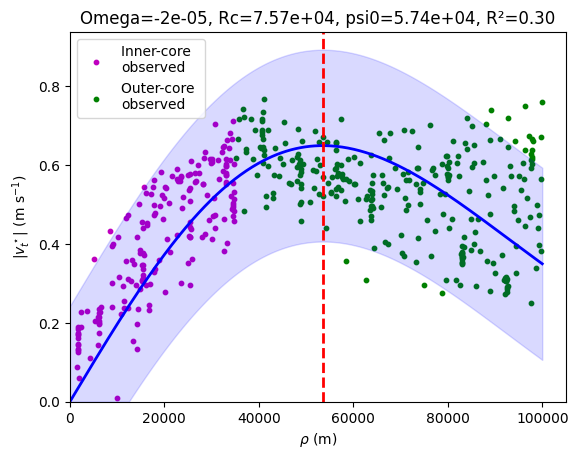

In [4]:
seed_Q = np.asarray(analysis["initial_Q"], float)
selector_options = dict(z_target=analysis["depth_m"],
                        xc_pre=analysis["initial_center_m"][0], yc_pre=analysis["initial_center_m"][1],
                        q11=seed_Q[0, 0], q12=seed_Q[0, 1], q22=seed_Q[1, 1],
                        rho_core=analysis["core_radius_m"], rho_outer=analysis["outer_radius_m"],
                        outer_fit_options=outer_fit_kwargs)
data_multi, df_xyuv_multi, df_rho_multi = latte_source_selector(ds_sadcp, ds_sat, source="multi", plot=plot_config["diagnostics"], **selector_options)
data_sadcp, df_xyuv_sadcp, df_rho_sadcp = latte_source_selector(ds_sadcp, ds_sat, source="sadcp", plot=False, **selector_options)
data_sat, df_xyuv_sat, df_rho_sat = latte_source_selector(ds_sadcp, ds_sat, source="sat", plot=False, **selector_options)

df_xyuv = pd.concat([df_xyuv_multi, df_xyuv_sadcp, df_xyuv_sat], ignore_index=True)
df_res = pd.concat([data_multi, data_sadcp, data_sat], ignore_index=True)
print("Selected multi-platform observations by stage and platform:")
print(df_xyuv_multi.groupby(["core", "platform"]).size())
print("Outer-fit observations after sign selection:")
print(df_rho_multi.platform.value_counts())
df_res


In [5]:
# Find R2
R2_vals = []
for (row, source) in zip([data_multi, data_sadcp, data_sat], ["multi", "sadcp", "sat"]):
    
    row = row.iloc[0]
    df = df_xyuv[df_xyuv.source == source]
    xi = df.xi.to_numpy(float)
    yi = df.yi.to_numpy(float)
    u  = df.ui.to_numpy(float)
    v  = df.vi.to_numpy(float)
    uhat, vhat = model_uv_at_xy(xi, yi, row.xc, row.yc, np.asarray(row.Q), row.Omega, row.Rc)
    R2_vals.append(vector_R2(u, v, uhat, vhat))

df_res['R2'] = R2_vals
df_res


,source,xc,yc,w,Q,Omega,Omega_core,w_core,fit_status,Rc,psi0,time,alpha,R2
0,multi,-377.930170,-435.057502,-0.000040,"[[1.1442577119098483, -0.04723794911498031], [...",-0.000020,-0.000019,-0.000039,optimized,75725.020630,57359.890779,2023-10-19 04:27:30.509622170,1.152329,0.905907
1,sadcp,-630.462766,-698.395388,-0.000042,"[[1.1304059939390516, -0.05256697764617616], [...",-0.000021,-0.000020,-0.000040,optimized,72519.778758,55298.531733,2023-10-19 04:27:30.509622170,1.141277,0.899772
2,sat,3955.263235,5415.311507,-0.000032,"[[1.2275743600236981, 0.025680312136149214], [...",-0.000016,-0.000015,-0.000031,optimized,90338.015000,64242.571817,2023-10-19 04:27:30.509622170,1.229167,0.966880


In [6]:
# Reconstruct velocity field using ESP parameters
sources = ["multi", "sadcp", "sat"]

U_all = []
V_all = []

X = ds_sat.x.values
Y = ds_sat.y.values
mask = ds_sat.land_mask.values

for s in sources:
    data = df_res[df_res.source == s].iloc[0]

    dx = X - data.xc
    dy = Y - data.yc
    q11, q12, q22 = data.Q[0,0], data.Q[0,1], data.Q[1,1]

    rho2 = q11*dx**2 + 2*q12*dx*dy + q22*dy**2
    fac = data.Omega * np.exp(-rho2 / data.Rc**2)

    U = -fac * (q12*dx + q22*dy)
    V =  fac * (q11*dx + q12*dy)

    U = np.where(mask, np.nan, U)
    V = np.where(mask, np.nan, V)

    U_all.append(U)
    V_all.append(V)

U_all = np.stack(U_all)
V_all = np.stack(V_all)

t = df_res.time.to_numpy(dtype="datetime64[ns]")[:1]

ds_model = xr.Dataset(
    data_vars=dict(
        u=(("source","time","lat","lon"), U_all[:,None,:,:]),
        v=(("source","time","lat","lon"), V_all[:,None,:,:]),
    ),
    coords=dict(
        source=sources,
        time=t,
        lat=ds_sat.lat.values,
        lon=ds_sat.lon.values,
        x=(("lat","lon"), X),
        y=(("lat","lon"), Y),
        land_mask=(("lat","lon"), mask),
    ),
)
ds_model


<xarray.Dataset> Size: 123kB
Dimensions:    (source: 3, time: 1, lat: 41, lon: 46)
Coordinates:
  * source     (source) <U5 60B 'multi' 'sadcp' 'sat'
  * time       (time) datetime64[ns] 8B 2023-10-19T04:27:30.509622170
  * lat        (lat) float64 328B -42.0 -41.8 -41.6 -41.4 ... -34.4 -34.2 -34.0
  * lon        (lon) float64 368B 149.0 149.2 149.4 149.6 ... 157.6 157.8 158.0
    x          (lat, lon) float64 15kB -4.642e+05 -4.467e+05 ... 3.241e+05
    y          (lat, lon) float64 15kB -4.551e+05 -4.551e+05 ... 4.329e+05
    land_mask  (lat, lon) bool 2kB False False False False ... False False False
Data variables:
    u          (source, time, lat, lon) float64 45kB -1.065e-30 ... 5.67e-15
    v          (source, time, lat, lon) float64 45kB 1.442e-30 ... -6.421e-15

In [7]:
def plot_model(source, df_res, ds_sat, ds_model, df_xyuv, spac=1, scale=20,
                      xlim=(-170, 170), ylim=(-170, 170), out_thresh=False, plot_data=False, fit_details=None):

    data = df_res[df_res.source == source].iloc[0]
    df_xyuv = df_xyuv.copy()
    df_xyuv = df_xyuv[df_xyuv.source == source]
    time = data.time
    if not np.isfinite([data.Omega, data.Rc]).all() or data.Rc <= 0:
        print("Gaussian figure unavailable at", time, ":", data.get("fit_status", "invalid outer fit"))
        return

    sat = interpolate_satellite_at_time(ds_sat, time)
    mod = ds_model.sel(source=source).sel(time=time, method="nearest")#.squeeze("time")

    X = sat.x.values / 1e3
    Y = sat.y.values / 1e3

    us, vs = sat.u.values, sat.v.values
    um, vm = mod.u.values, mod.v.values

    sp_s = np.hypot(us, vs)
    sp_m = np.hypot(um, vm)

    dx, dy = sat.x.values - data.xc, sat.y.values - data.yc
    q11, q12, q22 = data.Q[0,0], data.Q[0,1], data.Q[1,1]
    rho2 = q11*dx**2 + 2*q12*dx*dy + q22*dy**2

    roi = (X >= xlim[0]) & (X <= xlim[1]) & (Y >= ylim[0]) & (Y <= ylim[1])
    sp_s_roi = np.where(roi, sp_s, np.nan)
    sp_m_roi = np.where(roi, sp_m, np.nan)
    roi_quiv = roi & (rho2 >= analysis["outer_radius_m"]**2)

    vals = np.concatenate([sp_s_roi[roi], sp_m_roi[roi]])
    vmin, vmax = np.nanmin(vals), np.nanmax(vals)
    levels = np.arange(0, vmax+.05, .05)

    X_rho, Y_rho = np.meshgrid(np.linspace(xlim[0]*1e3, xlim[1]*1e3, 100), np.linspace(ylim[0]*1e3, ylim[1]*1e3, 100))
    dx = X_rho - data.xc
    dy = Y_rho - data.yc
    q11, q12, q22 = data.Q[0,0], data.Q[0,1], data.Q[1,1]
    rho2 = q11*dx**2 + 2*q12*dx*dy + q22*dy**2

    fig, axs = plt.subplots(1, 3, figsize=(16,5), constrained_layout=True) #sharex=True, sharey=True

    # Satellite
    h0 = axs[0].contourf(X, Y, sp_s_roi, levels=levels, cmap="Blues_r")
    axs[0].quiver(X[::spac,::spac], Y[::spac,::spac],
                  np.where(roi_quiv[::spac,::spac], us[::spac,::spac], np.nan),
                  np.where(roi_quiv[::spac,::spac], vs[::spac,::spac], np.nan),
                  scale=scale, alpha=.4, width=.0015)
    axs[0].scatter(data.xc/1e3, data.yc/1e3, marker="x", color="r", s=50)
    axs[0].contour(X_rho/1e3, Y_rho/1e3, rho2, levels=[((data.Rc)**2)/2], colors="r", linewidths=2, linestyles="--")
    dsrc = df_res[df_res.source == source]
    axs[0].plot(dsrc.xc/1e3, dsrc.yc/1e3, color="r", lw=.5)
    if plot_data:
        df = df_xyuv.copy()
        df = df_xyuv[(df_xyuv.source==source)&(df_xyuv.core=='outer')]
        axs[0].quiver(df.xi/1e3, df.yi/1e3, df.ui, df.vi, scale=scale, width=.0025, color='g', label='Outer-core data')
        df = df_xyuv[(df_xyuv.source==source)&(df_xyuv.core=='inner')]
        axs[0].quiver(df.xi/1e3, df.yi/1e3, df.ui, df.vi, scale=scale, width=.0025, color='m', label='Inner-core data')
    # axs[0].set_title("Satellite");
    axs[0].set_aspect("equal"); axs[0].legend(loc='lower right')

    # Model
    h1 = axs[1].contourf(X, Y, sp_m_roi, levels=levels, cmap="Blues_r")
    axs[1].quiver(X[::spac,::spac], Y[::spac,::spac],
                  np.where(roi[::spac,::spac], um[::spac,::spac], np.nan),
                  np.where(roi[::spac,::spac], vm[::spac,::spac], np.nan),
                  scale=scale, alpha=.5)
    axs[1].scatter(data.xc/1e3, data.yc/1e3, marker="x", color="r", s=50, label='Eddy center')
    axs[1].contour(X_rho/1e3, Y_rho/1e3, rho2, levels=[(data.Rc**2)/2], colors="r", linewidths=2, linestyles="--")
    axs[1].plot([np.nan, np.nan], [np.nan, np.nan], lw=2, color='r', label='Max tangential\nvelocity', ls='--')
    # axs[1].set_title("Model - LATTE with S-ADCP and Satellite Data")
    axs[1].set_aspect("equal"); axs[1].legend(loc='lower right')

    gap = 20
    for ax in [axs[0], axs[1]]:
        # ax.axis('equal')
        ax.set_xlim(xlim[0]+gap, xlim[1]-gap)
        ax.set_ylim(ylim[0]+gap, ylim[1]-gap)
        ax.set_xlabel("x (km)")
        
        ax.set_ylabel("y (km)")

    axs[0].text(-0.1, 1.07, "a)", transform=axs[0].transAxes, fontsize=13, fontweight="bold", va="top", ha="left")
    axs[1].text(-0.1, 1.07, "b)", transform=axs[1].transAxes, fontsize=13, fontweight="bold", va="top", ha="left")

    fig.colorbar(h1, ax=axs[1], label=r"Current speed (ms$^{-1}$)", fraction=0.05, pad=0.02)

    if fit_details is None:
        raise ValueError("Pass the stored outer-fit diagnostics for this source; plotting must not refit.")
    plot_outer_core_fit(fit_details, ax=axs[2], km_flag=True, pred_flag=True)
    axs[2].set_title('')
    axs[2].set_xlabel(r'$\rho$ (km)')
    axs[2].set_ylabel(r'|Normalised tangential velocity| (ms$^{-1}$)')
    axs[2].text(-0.1, 1.07, "c)", transform=axs[2].transAxes, fontsize=13, fontweight="bold", va="top", ha="left")
    axs[2].get_legend().remove()
    
    plt.show()
    return fig


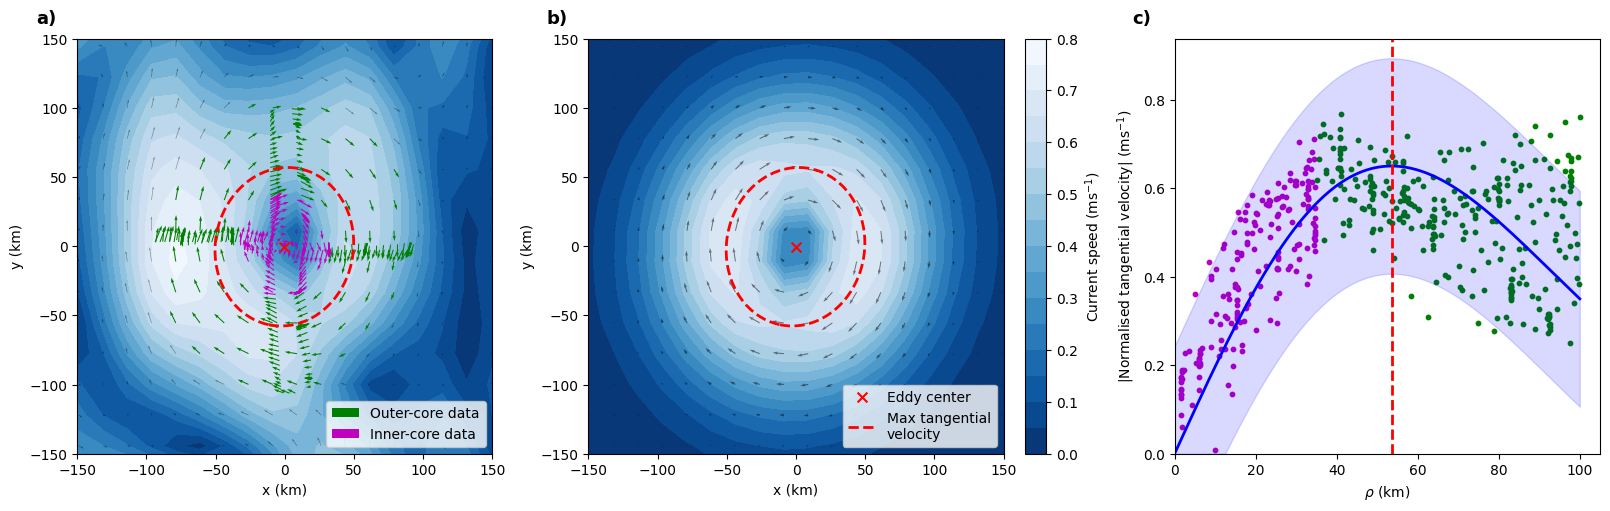

PosixPath('/Users/regdowse/Desktop/local_files/PhD/elliptical_streamfunction_parametrisation/results/manuscript_figures/latte_sadcp_sat.png')

In [8]:
fit_by_source = {"multi": df_rho_multi, "sadcp": df_rho_sadcp, "sat": df_rho_sat}
manuscript_figure = plot_model(plot_config["source"], df_res, ds_sat, ds_model, df_xyuv,
           spac=plot_config["quiver_spacing"], scale=plot_config["quiver_scale"],
           xlim=plot_config["x_limits_km"], ylim=plot_config["y_limits_km"],
           plot_data=plot_config["plot_data"],
           fit_details=fit_by_source[plot_config["source"]].attrs["outer_fit"])

save_manuscript_figure(manuscript_figure, "latte_sadcp_sat",
    repo_path(REPO_ROOT, config["output_dir"]), dpi=300, bbox_inches="tight")


In [9]:
# Results
df_paper = df_res.copy()
df_paper = df_paper.drop(columns='Q')
df_paper


,source,xc,yc,w,Omega,Omega_core,w_core,fit_status,Rc,psi0,time,alpha,R2
0,multi,-377.930170,-435.057502,-0.000040,-0.000020,-0.000019,-0.000039,optimized,75725.020630,57359.890779,2023-10-19 04:27:30.509622170,1.152329,0.905907
1,sadcp,-630.462766,-698.395388,-0.000042,-0.000021,-0.000020,-0.000040,optimized,72519.778758,55298.531733,2023-10-19 04:27:30.509622170,1.141277,0.899772
2,sat,3955.263235,5415.311507,-0.000032,-0.000016,-0.000015,-0.000031,optimized,90338.015000,64242.571817,2023-10-19 04:27:30.509622170,1.229167,0.966880


### Manuscript results summary
Computed from this run. All dates are UTC; final refined parameters are reported.
This notebook demonstrates ESP on real data; idealised experiments are outside its scope.

In [10]:
with capture_summary() as manuscript_text:
    from reporting import print_manuscript_summary, fit_record, evaluation_counts

    target = ds_sadcp.time.mean().values
    sat_times = ds_sat.time.values
    bracket_left = sat_times[sat_times <= target][-1]
    bracket_right = sat_times[sat_times >= target][0]
    selection_settings = df_rho_multi.attrs["settings"]
    summary_counts = pd.DataFrame([
        row for samples in [df_rho_multi, df_rho_sadcp, df_rho_sat]
        for row in samples.attrs.get("selection_counts", [])])
    print_manuscript_summary(
        "LATTE — S-ADCP and satellite", df_res,
        {"ADCP interval": f"{ds_sadcp.time.values[0]} to {ds_sadcp.time.values[-1]} UTC",
         "ADCP duration (days)": (ds_sadcp.time.values[-1] - ds_sadcp.time.values[0]) / np.timedelta64(1, "D"),
         "ADCP candidate count": ds_sadcp.sizes["time"],
         "Selected depth (m)": selection_settings["z"],
         "Satellite interpolation target": f"{target} UTC",
         "Native satellite brackets": f"{bracket_left} and {bracket_right} UTC",
         "MAT UTC correction": "-12 h; satellite clock unchanged",
         "Local origin (longitude, latitude)": (theta_mean, phi_mean),
         "Initial centre (m)": (selection_settings["xc_pre"], selection_settings["yc_pre"]),
         "Initial/refined inner radius (km)": selection_settings["rho_core"] / 1000,
         "Outer elliptical radius limit (km)": selection_settings["rho_outer"] / 1000},
        counts=summary_counts,
        outer_records=[fit_record(df_res[df_res.source == source].iloc[0].time,
                                   samples.attrs.get("outer_fit", {}), source)
                       for source, samples in [("multi", df_rho_multi), ("sadcp", df_rho_sadcp), ("sat", df_rho_sat)]],
        notes=["Velocity R² uses the returned inner + outer-only evaluation rows for each source.",
               "Finite velocity-R² evaluation counts: " + evaluation_counts(df_xyuv).to_string(index=False),
               "Outer-fit counts include retained inner observations; outer-only plot colours exclude them.",
               "Shading is an approximate 95% prediction interval; space/time correlation is ignored."],
        input_files=["applications/LATTE_app1_multiplatform_data.ipynb", *config["inputs"].values()], root=REPO_ROOT)

export_directory = export_application_results(
    REPO_ROOT, CONFIG_PATH, config,
    df_res, manuscript_text.getvalue(),
    notebook="applications/LATTE_app1_multiplatform_data.ipynb",
    tables={"observation_counts": summary_counts, "outer_fit_diagnostics": pd.DataFrame([fit_record(ds_sadcp.time.mean().values, samples.attrs["outer_fit"], source) for source, samples in fit_by_source.items()])},
    run_info={"raw_adcp_indices": ds_sadcp.raw_index.values, "mean_adcp_time_utc": ds_sadcp.time.mean().values})



MANUSCRIPT RESULTS SUMMARY — LATTE — S-ADCP and satellite
Current run; compare with the manuscript after any analysis change. All times UTC.

DATA AND SETTINGS
  ADCP interval: 2023-10-16T22:27:31.000004000 to 2023-10-21T10:27:30.333340000 UTC
  ADCP duration (days): 4.499992283981482
  ADCP candidate count: 433
  Selected depth (m): 37.0
  Satellite interpolation target: 2023-10-19T04:27:30.509622170 UTC
  Native satellite brackets: 2023-10-18T18:00:00.000000000 and 2023-10-19T18:00:00.000000000 UTC
  MAT UTC correction: -12 h; satellite clock unchanged
  Local origin (longitude, latitude): (154.3, -37.9)
  Initial centre (m): (0.0, 0.0)
  Initial/refined inner radius (km): 35.0
  Outer elliptical radius limit (km): 100.0

MANUSCRIPT-ROUNDED VALUES (final refined Omega; omega = Omega tr(Q))
  multi, 2023-10-19 04:27:30.509622170 UTC: (x0,y0)=(-0.4, -0.4) km; omega=-4.0e-05 s^-1; Omega=-2.0e-05 s^-1; alpha=1.15; Rc=75.7 km; psi0=57359.9 m^2/s; R²_velocity=0.91
  sadcp, 2023-10-19 04:2